## Step 1–3: Install and Import Required Libraries

In [ ]:
# Install required libraries
!pip install nltk spacy gensim wordcloud matplotlib -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 32.8 MB/s eta 0:00:00


In [ ]:
import string
import re
import matplotlib.pyplot as plt

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.probability import FreqDist

from wordcloud import WordCloud
from gensim.models import Word2Vec

print("Libraries imported successfully.")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported successfully.


## Step 4: Load Sample Paragraph (200+ words)

In [ ]:
text = """
Generative Artificial Intelligence is rapidly transforming the way humans interact with
technology across nearly every industry in the modern world. From intelligent tutoring
systems in education to automated content creation in media, generative AI models are
enabling machines to understand, summarize, and even generate human-like language with
remarkable fluency. Natural Language Processing, often abbreviated as NLP, forms the
foundation of these systems by allowing computers to process and interpret unstructured
text data. Before any machine learning or transformer-based model can make sense of
language, the raw text must undergo a series of preprocessing steps such as lowercasing,
punctuation removal, and tokenization. Tokenization breaks down large chunks of text into
smaller, manageable units called tokens, which may represent words, subwords, or even
individual characters depending on the technique used. Stop words, which are common words
like "is", "the", and "of", are often removed because they add little semantic value to
the analysis. Stemming and lemmatization further refine the text by reducing words to
their root or base forms, helping models generalize better across different word variants.
Once the text has been cleaned and normalized, it can be converted into numerical vectors
known as word embeddings. These embeddings, generated using techniques such as Word2Vec,
GloVe, or FastText, capture semantic relationships between words by placing similar words
closer together in a high-dimensional vector space. Transformer-based large language
models, including BERT and GPT, rely on advanced subword tokenization strategies such as
WordPiece and Byte Pair Encoding to efficiently handle vast vocabularies and rare words.
Understanding these foundational preprocessing and embedding techniques is essential for
anyone working in the field of natural language processing, as they directly influence the
performance, efficiency, and accuracy of downstream tasks such as text classification,
sentiment analysis, machine translation, summarization, and question answering systems.
"""

print("Original Text:\n")
print(text)
print("\nWord count:", len(text.split()))


Original Text:


Generative Artificial Intelligence is rapidly transforming the way humans interact with
technology across nearly every industry in the modern world. From intelligent tutoring
systems in education to automated content creation in media, generative AI models are
enabling machines to understand, summarize, and even generate human-like language with
remarkable fluency. Natural Language Processing, often abbreviated as NLP, forms the
foundation of these systems by allowing computers to process and interpret unstructured
text data. Before any machine learning or transformer-based model can make sense of
language, the raw text must undergo a series of preprocessing steps such as lowercasing,
punctuation removal, and tokenization. Tokenization breaks down large chunks of text into
smaller, manageable units called tokens, which may represent words, subwords, or even
individual characters depending on the technique used. Stop words, which are common words
like "is", "the", and "

## Step 5: Convert Text to Lowercase

In [ ]:
text_lower = text.lower()
print(text_lower)



generative artificial intelligence is rapidly transforming the way humans interact with
technology across nearly every industry in the modern world. from intelligent tutoring
systems in education to automated content creation in media, generative ai models are
enabling machines to understand, summarize, and even generate human-like language with
remarkable fluency. natural language processing, often abbreviated as nlp, forms the
foundation of these systems by allowing computers to process and interpret unstructured
text data. before any machine learning or transformer-based model can make sense of
language, the raw text must undergo a series of preprocessing steps such as lowercasing,
punctuation removal, and tokenization. tokenization breaks down large chunks of text into
smaller, manageable units called tokens, which may represent words, subwords, or even
individual characters depending on the technique used. stop words, which are common words
like "is", "the", and "of", are often r

## Step 6: Remove Punctuation and Special Characters

In [ ]:
text_clean = text_lower.translate(str.maketrans('', '', string.punctuation))
text_clean = re.sub(r'\s+', ' ', text_clean).strip()
print(text_clean)


generative artificial intelligence is rapidly transforming the way humans interact with technology across nearly every industry in the modern world from intelligent tutoring systems in education to automated content creation in media generative ai models are enabling machines to understand summarize and even generate humanlike language with remarkable fluency natural language processing often abbreviated as nlp forms the foundation of these systems by allowing computers to process and interpret unstructured text data before any machine learning or transformerbased model can make sense of language the raw text must undergo a series of preprocessing steps such as lowercasing punctuation removal and tokenization tokenization breaks down large chunks of text into smaller manageable units called tokens which may represent words subwords or even individual characters depending on the technique used stop words which are common words like is the and of are often removed because they add little

## Step 7: Tokenization

In [ ]:
tokens = word_tokenize(text_clean)
print("Number of tokens:", len(tokens))
print(tokens)


Number of tokens: 294
['generative', 'artificial', 'intelligence', 'is', 'rapidly', 'transforming', 'the', 'way', 'humans', 'interact', 'with', 'technology', 'across', 'nearly', 'every', 'industry', 'in', 'the', 'modern', 'world', 'from', 'intelligent', 'tutoring', 'systems', 'in', 'education', 'to', 'automated', 'content', 'creation', 'in', 'media', 'generative', 'ai', 'models', 'are', 'enabling', 'machines', 'to', 'understand', 'summarize', 'and', 'even', 'generate', 'humanlike', 'language', 'with', 'remarkable', 'fluency', 'natural', 'language', 'processing', 'often', 'abbreviated', 'as', 'nlp', 'forms', 'the', 'foundation', 'of', 'these', 'systems', 'by', 'allowing', 'computers', 'to', 'process', 'and', 'interpret', 'unstructured', 'text', 'data', 'before', 'any', 'machine', 'learning', 'or', 'transformerbased', 'model', 'can', 'make', 'sense', 'of', 'language', 'the', 'raw', 'text', 'must', 'undergo', 'a', 'series', 'of', 'preprocessing', 'steps', 'such', 'as', 'lowercasing', 'pun

## Step 8: Remove English Stop Words

In [ ]:
stop_words = set(stopwords.words('english'))
filtered_tokens = [w for w in tokens if w.isalpha() and w not in stop_words]

print("Number of tokens after stopword removal:", len(filtered_tokens))
print(filtered_tokens)


Number of tokens after stopword removal: 197
['generative', 'artificial', 'intelligence', 'rapidly', 'transforming', 'way', 'humans', 'interact', 'technology', 'across', 'nearly', 'every', 'industry', 'modern', 'world', 'intelligent', 'tutoring', 'systems', 'education', 'automated', 'content', 'creation', 'media', 'generative', 'ai', 'models', 'enabling', 'machines', 'understand', 'summarize', 'even', 'generate', 'humanlike', 'language', 'remarkable', 'fluency', 'natural', 'language', 'processing', 'often', 'abbreviated', 'nlp', 'forms', 'foundation', 'systems', 'allowing', 'computers', 'process', 'interpret', 'unstructured', 'text', 'data', 'machine', 'learning', 'transformerbased', 'model', 'make', 'sense', 'language', 'raw', 'text', 'must', 'undergo', 'series', 'preprocessing', 'steps', 'lowercasing', 'punctuation', 'removal', 'tokenization', 'tokenization', 'breaks', 'large', 'chunks', 'text', 'smaller', 'manageable', 'units', 'called', 'tokens', 'may', 'represent', 'words', 'subwo

## Step 9: Stemming using Porter Stemmer

In [ ]:
stemmer = PorterStemmer()
stemmed_tokens = [stemmer.stem(w) for w in filtered_tokens]
print(stemmed_tokens)


['gener', 'artifici', 'intellig', 'rapidli', 'transform', 'way', 'human', 'interact', 'technolog', 'across', 'nearli', 'everi', 'industri', 'modern', 'world', 'intellig', 'tutor', 'system', 'educ', 'autom', 'content', 'creation', 'media', 'gener', 'ai', 'model', 'enabl', 'machin', 'understand', 'summar', 'even', 'gener', 'humanlik', 'languag', 'remark', 'fluenci', 'natur', 'languag', 'process', 'often', 'abbrevi', 'nlp', 'form', 'foundat', 'system', 'allow', 'comput', 'process', 'interpret', 'unstructur', 'text', 'data', 'machin', 'learn', 'transformerbas', 'model', 'make', 'sens', 'languag', 'raw', 'text', 'must', 'undergo', 'seri', 'preprocess', 'step', 'lowercas', 'punctuat', 'remov', 'token', 'token', 'break', 'larg', 'chunk', 'text', 'smaller', 'manag', 'unit', 'call', 'token', 'may', 'repres', 'word', 'subword', 'even', 'individu', 'charact', 'depend', 'techniqu', 'use', 'stop', 'word', 'common', 'word', 'like', 'often', 'remov', 'add', 'littl', 'semant', 'valu', 'analysi', 'stem

## Step 10: Lemmatization using WordNetLemmatizer

In [ ]:
lemmatizer = WordNetLemmatizer()
lemmatized_tokens = [lemmatizer.lemmatize(w) for w in filtered_tokens]
print(lemmatized_tokens)


['generative', 'artificial', 'intelligence', 'rapidly', 'transforming', 'way', 'human', 'interact', 'technology', 'across', 'nearly', 'every', 'industry', 'modern', 'world', 'intelligent', 'tutoring', 'system', 'education', 'automated', 'content', 'creation', 'medium', 'generative', 'ai', 'model', 'enabling', 'machine', 'understand', 'summarize', 'even', 'generate', 'humanlike', 'language', 'remarkable', 'fluency', 'natural', 'language', 'processing', 'often', 'abbreviated', 'nlp', 'form', 'foundation', 'system', 'allowing', 'computer', 'process', 'interpret', 'unstructured', 'text', 'data', 'machine', 'learning', 'transformerbased', 'model', 'make', 'sense', 'language', 'raw', 'text', 'must', 'undergo', 'series', 'preprocessing', 'step', 'lowercasing', 'punctuation', 'removal', 'tokenization', 'tokenization', 'break', 'large', 'chunk', 'text', 'smaller', 'manageable', 'unit', 'called', 'token', 'may', 'represent', 'word', 'subwords', 'even', 'individual', 'character', 'depending', 'te

## Step 11: Frequency Distribution of Processed Words

Top 15 most frequent words:
word: 9
text: 6
language: 5
model: 4
system: 3
machine: 3
tokenization: 3
technique: 3
generative: 2
across: 2
even: 2
natural: 2
processing: 2
often: 2
form: 2


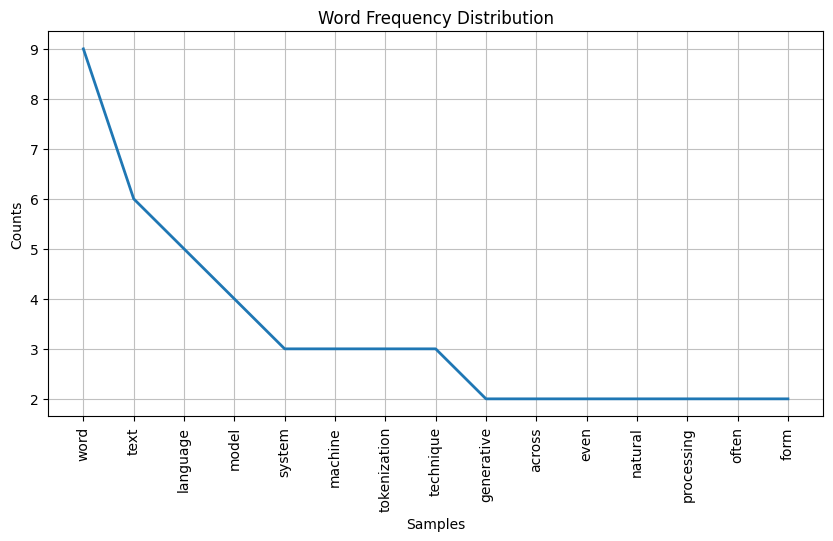

In [ ]:
freq_dist = FreqDist(lemmatized_tokens)

print("Top 15 most frequent words:")
for word, freq in freq_dist.most_common(15):
    print(f"{word}: {freq}")

# Plot frequency distribution
plt.figure(figsize=(10, 5))
freq_dist.plot(15, cumulative=False)
plt.title("Word Frequency Distribution")
plt.show()


## Step 12: Generate Word Cloud

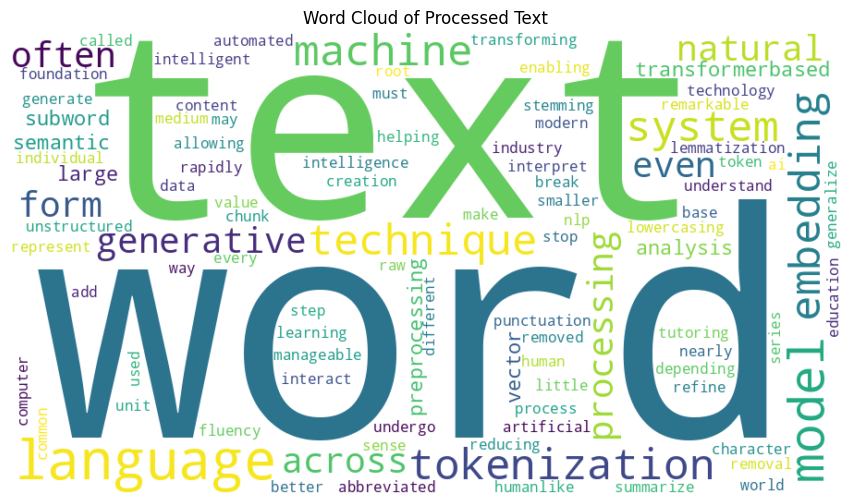

In [ ]:
wordcloud_text = ' '.join(lemmatized_tokens)

wc = WordCloud(width=900, height=500, background_color='white',
               colormap='viridis', max_words=100).generate(wordcloud_text)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Processed Text")
plt.show()


## Step 13: Create Word2Vec Embeddings using Gensim\n\nFor a more robust embedding model, we train on the tokenized sentences of the cleaned text (a single paragraph gives a small vocabulary, so results are illustrative).

In [ ]:
# Prepare sentence-level tokenized corpus for Word2Vec training
raw_sentences = re.split(r'[.!?]', text_clean)
corpus = []
for sent in raw_sentences:
    sent_tokens = word_tokenize(sent)
    sent_tokens = [w for w in sent_tokens if w.isalpha() and w not in stop_words]
    if sent_tokens:
        corpus.append(sent_tokens)

print(f"Number of training sentences: {len(corpus)}")

model = Word2Vec(sentences=corpus, vector_size=100, window=5, min_count=1, workers=4, seed=42)
print("Word2Vec model trained successfully.")
print("Vocabulary size:", len(model.wv.index_to_key))


Number of training sentences: 1
Word2Vec model trained successfully.
Vocabulary size: 160


## Step 14: Display Embedding Vector of Five Selected Words

In [ ]:
selected_words = ['generative', 'language', 'tokenization', 'model', 'text']

for word in selected_words:
    if word in model.wv:
        vector = model.wv[word]
        print(f"\nWord: '{word}'")
        print(f"Vector shape: {vector.shape}")
        print(f"First 10 dimensions: {vector[:10]}")
    else:
        print(f"'{word}' not found in vocabulary.")



Word: 'generative'
Vector shape: (100,)
First 10 dimensions: [ 0.00826777  0.00337045 -0.00656041 -0.0074046   0.00742748 -0.00448807
  0.00533246 -0.00722177 -0.00439909 -0.00432521]

Word: 'language'
Vector shape: (100,)
First 10 dimensions: [-0.00265898  0.00821403 -0.0001074   0.00401477 -0.0008715  -0.00464858
  0.00532383  0.00939512 -0.00476097  0.00557335]

Word: 'tokenization'
Vector shape: (100,)
First 10 dimensions: [-0.00270658  0.0065728  -0.00980685  0.00791858  0.00083038 -0.00716811
 -0.0039067   0.00109496 -0.00372084 -0.00783086]

Word: 'model'
Vector shape: (100,)
First 10 dimensions: [ 0.00015854 -0.00088593 -0.00855081 -0.00762273  0.00190245  0.00138809
  0.00110001 -0.00687322  0.00019392 -0.00878347]

Word: 'text'
Vector shape: (100,)
First 10 dimensions: [ 0.00669923 -0.00593409  0.00608592 -0.00985105  0.00591212  0.00577436
  0.00567632  0.00331323 -0.00061864  0.00408888]


## Step 15: Find Three Most Similar Words for a Selected Keyword

In [ ]:
keyword = 'language'

if keyword in model.wv:
    similar_words = model.wv.most_similar(keyword, topn=3)
    print(f"Top 3 words most similar to '{keyword}':")
    for word, score in similar_words:
        print(f"  {word}: {score:.4f}")
else:
    print(f"'{keyword}' not found in vocabulary.")


Top 3 words most similar to 'language':
  technology: 0.2529
  smaller: 0.2422
  closer: 0.2172
